In [1]:
def allInOne(path):

    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt

    def filterArraysToShortest(arr1, arr1Pos, arr2, arr2Pos):
        both_pos = np.logical_and(arr1Pos, arr2Pos)
        arr1Filt = arr1[both_pos] 
        arr2Filt = arr2[both_pos] 
    
        return arr1Filt, arr2Filt
    
    
    def filterArraysToShortest2(arr1, arr1Pos, arr2, arr2Pos):
        if np.count_nonzero(arr1Pos) < np.count_nonzero(arr2Pos):
            arr1Filt = arr1[arr1Pos] 
            arr2Filt = arr2[arr1Pos] 
        else:
            arr1Filt = arr1[arr2Pos] 
            arr2Filt = arr2[arr2Pos] 
            
        return arr1Filt, arr2Filt
    
    df = pd.read_csv(path)
    display(df.head(5))
    
    reps = df['rep'].to_numpy()
    hopsRanked = df['hopsRanked'].to_numpy()
    hopsUnranked = df['hopsUnranked'].to_numpy()
    hopsRankedOne = df['hopsRankedOne'].to_numpy()
    hopsPath = df['hopsPath'].to_numpy()

    hopsRankedPositive = hopsRanked > -1
    hopsUnrankedPositive = hopsUnranked > -1
    hopsRankedOnePositive = hopsRankedOne > -1
    hopsPathPositive = hopsPath > -1
    
    total = len(df.index)

    successesRanked = np.count_nonzero(hopsRanked > -1)
    successesRankedOne = np.count_nonzero(hopsRankedOne > -1)
    successesUnranked = np.count_nonzero(hopsUnranked > -1)
    successesPath = np.count_nonzero(hopsPath > -1)

    print("Resilience Paths: {}%".format((successesPath / total) * 100))
    print("Resilience One Tree: {}%".format((successesRankedOne / total) * 100))
    print("Resilience Trees: {}%".format((successesRanked / total) * 100))
    #print("Resilience Unranked: {}%".format((successesUnranked / total) * 100))

  
    hopsPathFiltered,hopsRankedFiltered = filterArraysToShortest(hopsPath, hopsPathPositive, hopsRanked, hopsRankedPositive)   
    
    diff = np.subtract(hopsPathFiltered,hopsRankedFiltered)
    plt.scatter(np.arange(len(hopsPathFiltered)), diff, color="blue", s=1.5)
    plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)

    print("Trees beat paths in {} runs".format(higherZero))
    print("Paths beat trees in {} runs".format(lowerZero))
    print("Both performed equally good in {} runs".format(equalZero))
    

    hopsPathFiltered,hopsRankedOneFiltered = filterArraysToShortest(hopsPath, hopsPathPositive, hopsRankedOne, hopsRankedOnePositive)   

    diff = np.subtract(hopsPathFiltered,hopsRankedOneFiltered)
    plt.scatter(np.arange(len(hopsPathFiltered)), diff, color="blue", s=1.5);
    plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)

    print("One Tree beat paths in {} runs".format(higherZero))
    print("Paths beat one tree in {} runs".format(lowerZero))
    print("Both performed equally good in {} runs".format(equalZero))




    hopsRankedOneFiltered,hopsRankedFiltered = filterArraysToShortest(hopsRankedOne, hopsRankedOnePositive, hopsRanked, hopsRankedPositive)   

    diff = np.subtract(hopsRankedOneFiltered,hopsRankedFiltered)
    plt.scatter(np.arange(len(hopsRankedFiltered)), diff, color="blue", s=1.5);
    plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)

    print("Multiple Trees beat One Tree in {} runs".format(higherZero))
    print("One Tree beat  multiple trees in {} runs".format(lowerZero))
    print("Both performed equally good in {} runs".format(equalZero))




    hopsUnrankedFiltered,hopsRankedFiltered = filterArraysToShortest(hopsUnranked, hopsUnrankedPositive, hopsRanked, hopsRankedPositive)   

    diff = np.subtract(hopsUnrankedFiltered,hopsRankedFiltered)
    plt.scatter(np.arange(len(hopsRankedFiltered)), diff, color="blue", s=1.5);
    plt.show()

    higherZero = np.count_nonzero(diff > 0)
    lowerZero = np.count_nonzero(diff < 0)
    equalZero = np.count_nonzero(diff == 0)

    print("Ranked Trees beat Unranked Tree in {} runs".format(higherZero))
    print("Unranked Tree beat ranked trees in {} runs".format(lowerZero))
    print("Both performed equally good in {} runs".format(equalZero))

## CLUSTERED, 60%, -30% per hop

,rep,nrNodes,nrEdges,edgeProb,nrPaths,nrFails,failureModel,failurePercent,hopsRanked,hopsUnranked,spLength,stretch_mult,nodeAdditions,hopsPath,stretch_path,hopsRankedOne,hopsUnrankedOne,stretch_one,overallNodeAdditionsOne,treeChoice
0,999,25,56,graphml/AttMpls.graphml,9,8,clustered,0.6;-0.3,2,2,2,0,0,4,2,2,2,0,0,shortest
1,998,25,56,graphml/AttMpls.graphml,3,2,clustered,0.6;-0.3,5,5,3,2,0,10,7,5,5,2,0,shortest
2,997,25,56,graphml/AttMpls.graphml,2,1,clustered,0.6;-0.3,3,3,3,0,0,8,5,3,3,0,0,shortest
3,996,25,56,graphml/AttMpls.graphml,3,2,clustered,0.6;-0.3,3,3,3,0,0,3,0,5,5,2,0,shortest
4,995,25,56,graphml/AttMpls.graphml,2,1,clustered,0.6;-0.3,3,3,4,-1,12,-1,-5,3,3,-1,0,shortest


Resilience Paths: 65.8675799086758%
Resilience One Tree: 97.03196347031964%
Resilience Trees: 99.31506849315068%


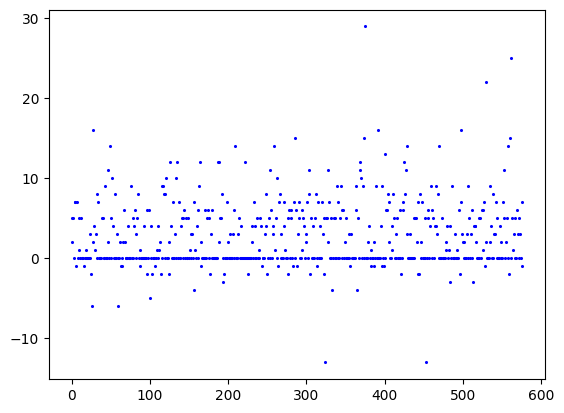

Trees beat paths in 291 runs
Paths beat trees in 47 runs
Both performed equally good in 239 runs


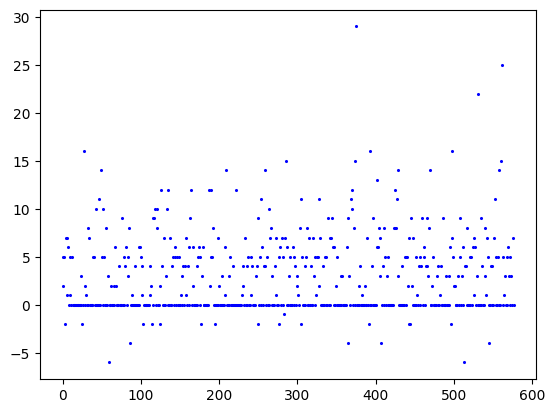

One Tree beat paths in 286 runs
Paths beat one tree in 21 runs
Both performed equally good in 270 runs


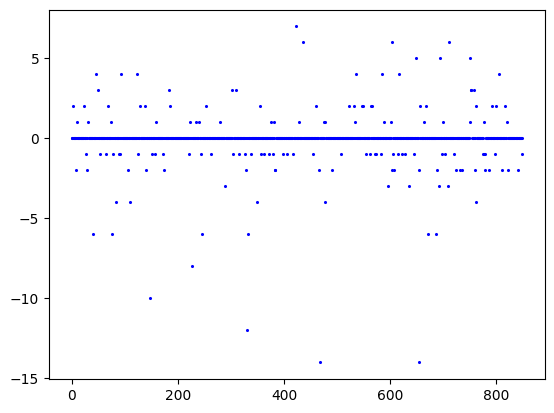

Multiple Trees beat One Tree in 63 runs
One Tree beat  multiple trees in 88 runs
Both performed equally good in 699 runs


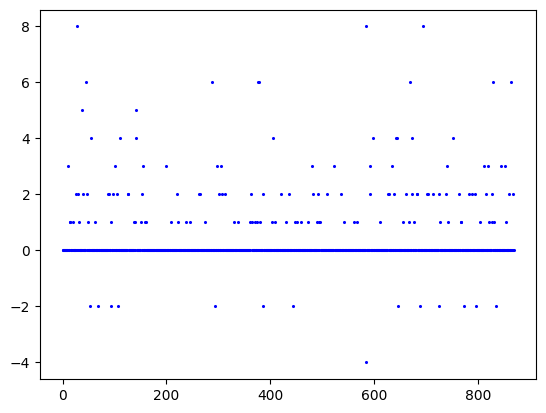

Ranked Trees beat Unranked Tree in 132 runs
Unranked Tree beat ranked trees in 14 runs
Both performed equally good in 724 runs


TypeError: cannot unpack non-iterable NoneType object

In [2]:
rPaths03, rOne03, rMult03 = allInOne("../../output/trees-2021-08-02_10-54-26-n25.csv")

## CLUSTERED, 50%, -15% per hop

In [ ]:
rPaths04, rOne04, rMult04 = allInOne('../../output/trees-2021-07-25_14-24-23-p0.05-n100.csv')


## Adversarial failures around D (varying failure rate)

In [ ]:
rPaths05, rOne05, rMult05 = allInOne('../../output/trees-2021-07-24_19-48-33-p0.05-n100.csv')

## Fixed adversarial failure rate 80%

In [ ]:
rPaths06, rOne06, rMult06 = allInOne('../../output/trees-2021-07-25_14-37-35-p0.05-n100.csv')


## AFTER BUGFIX

In [ ]:
allInOne('../../output/trees-2021-08-08_13-05-29-n25.csv')


In [ ]:
allInOne('../../output/trees-2021-08-08_13-09-49-n25.csv')


In [ ]:
allInOne('../../output/trees-2021-08-08_13-33-06-n25.csv')


### Reverse=False

In [ ]:
allInOne('../../output/trees-2021-08-08_14-32-46-n25.csv')



In [ ]:
allInOne('../../output/trees-2021-08-08_14-44-09-n197.csv')


In [ ]:
allInOne('../../output/trees-2021-08-08_14-45-37-n113.csv')


In [ ]:
allInOne('../../output/trees-2021-08-08_14-47-03-n149.csv')



In [ ]:
allInOne('../../output/trees-2021-08-08_14-48-35-n110.csv')



In [ ]:
allInOne('../../output/trees-2021-08-08_14-50-24-n93.csv')


In [ ]:
#adversarial failures 80%
allInOne('../../output/trees-2021-08-08_14-52-48-n113.csv')


In [ ]:
#adversarial failures 95%
allInOne('../../output/trees-2021-08-08_14-57-45-n113.csv')



In [ ]:
xVals = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
yValsPaths = [rPaths03, rPaths04, rPaths05, rPaths06, rPaths07, rPaths08, rPaths09]
yValsOne = [rOne03, rOne04, rOne05, rOne06, rOne07, rOne08, rOne09]
yValsMult = [rMult03, rMult04, rMult05, rMult06, rMult07, rMult08, rMult09]

In [ ]:
import matplotlib.pyplot as plt

plt.plot(xVals, yValsPaths, marker='o', markerfacecolor='blue', markersize=6, color='skyblue', linewidth=4)
plt.plot(xVals, yValsOne, marker='o', markerfacecolor='red', markersize=6, color='darkred', linewidth=4)
plt.plot(xVals, yValsMult, marker='o', markerfacecolor='green', markersize=6, color='darkgreen', linewidth=4)
plt.title('Resilience - Failure Rate')
plt.xlabel('Failure Rate')
plt.ylabel('Resilience')
plt.show()